<a href="https://colab.research.google.com/github/saaddatascience/nasa-flood-tracker/blob/main/flood_tracker_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

print("Flood Tracker Started")
print("Study Area: Pakistan")
print("Analysis: Before vs After Flood")


Flood Tracker Started
Study Area: Pakistan
Analysis: Before vs After Flood


In [2]:
from google.colab import files

Saving flood_sample.png.png to flood_sample.png.png
Image format: PNG
Image size: (1448, 1086)
Image mode: RGB


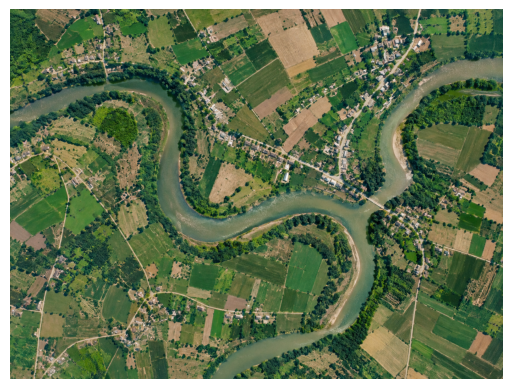

In [3]:

from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt

# Upload image from your laptop
uploaded = files.upload()

# Get the uploaded filename
filename = next(iter(uploaded))

# Open the image
img = Image.open(filename)

# Show image information
print("Image format:", img.format)
print("Image size:", img.size)
print("Image mode:", img.mode)

# Display the image
plt.imshow(img)
plt.axis("off")
plt.show()


Image format: PNG
Image size: (1448, 1086)
Image mode: RGB


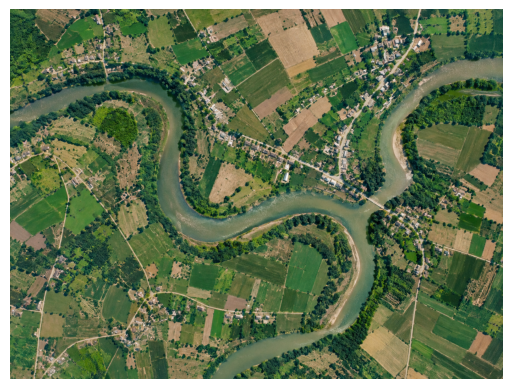

In [5]:

from PIL import Image
import matplotlib.pyplot as plt

img = Image.open("flood_sample.png.png")

print("Image format:", img.format)
print("Image size:", img.size)
print("Image mode:", img.mode)

plt.imshow(img)
plt.axis("off")
plt.show()


In [6]:

import numpy as np

# Convert the image into a NumPy array
img_array = np.array(img)

print("Array shape:", img_array.shape)
print("Array data type:", img_array.dtype)

# Show the RGB values of the first pixel
print("First pixel:", img_array[0, 0])


Array shape: (1086, 1448, 3)
Array data type: uint8
First pixel: [ 74 106  61]


In [7]:

# Select a small 3x3 region from the image
small_region = img_array[0:3, 0:3]

print("Small region shape:", small_region.shape)
print(small_region)


Small region shape: (3, 3, 3)
[[[ 74 106  61]
  [ 71 108  61]
  [ 68 111  61]]

 [[ 69 108  61]
  [ 72 119  63]
  [ 64 115  57]]

 [[ 67 107  56]
  [ 75 129  61]
  [ 72 128  58]]]


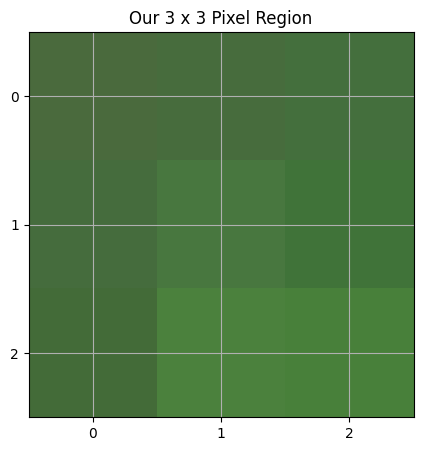

In [8]:

import matplotlib.pyplot as plt

plt.figure(figsize=(5, 5))
plt.imshow(small_region)
plt.title("Our 3 x 3 Pixel Region")
plt.xticks(range(3))
plt.yticks(range(3))
plt.grid()
plt.show()


Original shape: (1086, 1448, 3)
Grayscale shape: (1086, 1448)


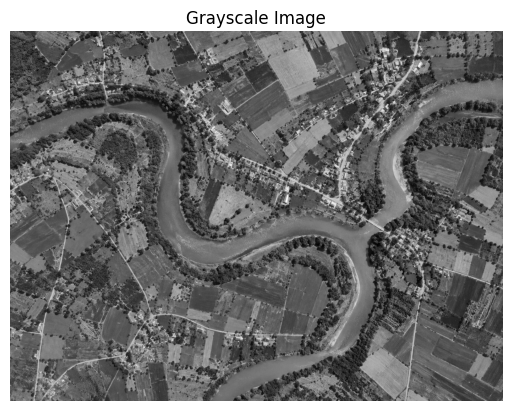

In [9]:

# Convert the RGB image into grayscale
gray_img = img.convert("L")

# Convert grayscale image into a NumPy array
gray_array = np.array(gray_img)

print("Original shape:", img_array.shape)
print("Grayscale shape:", gray_array.shape)

# Display grayscale image
plt.imshow(gray_array, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")
plt.show()


In [10]:
flooded = (before - after) > 0.3
print("Flooded pixels:", flooded.sum())

NameError: name 'before' is not defined

In [11]:
import numpy as np

before = np.full((100, 100), 0.6)

after = before.copy()
after[30:70, 30:70] = 0.1

flooded = (before - after) > 0.3
print("Flooded pixels:", flooded.sum())

Flooded pixels: 1600


In [12]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [14]:
import os
folder = "/content/drive/MyDrive/flood_project"
for f in os.listdir(folder):
    print(f)

S1A_IW_20220822T132759_DVP_RTC30_G_gpuned_3EFC_rgb.png
S1A_IW_20220822T132759_DVP_RTC30_G_gpuned_3EFC_inc_map.tif
S1A_IW_20220822T132759_DVP_RTC30_G_gpuned_3EFC_rgb.kmz
S1A_IW_20220822T132759_DVP_RTC30_G_gpuned_3EFC_rgb.png.aux.xml
S1A_IW_20220822T132759_DVP_RTC30_G_gpuned_3EFC_dem.tif
S1A_IW_20220822T132759_DVP_RTC30_G_gpuned_3EFC_ls_map.tif
S1A_IW_20220822T132759_DVP_RTC30_G_gpuned_3EFC.kmz
S1A_IW_20220822T132759_DVP_RTC30_G_gpuned_3EFC.png
S1A_IW_20220822T132759_DVP_RTC30_G_gpuned_3EFC.png.aux.xml
S1A_IW_20220822T132759_DVP_RTC30_G_gpuned_3EFC_VV.tif.xml
S1A_IW_20220822T132759_DVP_RTC30_G_gpuned_3EFC_shape.prj
S1A_IW_20220822T132759_DVP_RTC30_G_gpuned_3EFC_rgb.png.xml
S1A_IW_20220822T132759_DVP_RTC30_G_gpuned_3EFC_shape.shx
S1A_IW_20220822T132759_DVP_RTC30_G_gpuned_3EFC_inc_map.tif.xml
S1A_IW_20220822T132759_DVP_RTC30_G_gpuned_3EFC.log
S1A_IW_20220822T132759_DVP_RTC30_G_gpuned_3EFC_VH.tif.xml
S1A_IW_20220822T132759_DVP_RTC30_G_gpuned_3EFC.README.md.txt
S1A_IW_20220822T132759_DVP_RTC

In [15]:
!pip install rasterio -q

import rasterio
import numpy as np
import matplotlib.pyplot as plt

folder = "/content/drive/MyDrive/flood_project/"
before_path = folder + "S1A_IW_20220623T132755_DVP_RTC30_G_gpuned_F99E_VV.tif"
after_path  = folder + "S1A_IW_20220822T132759_DVP_RTC30_G_gpuned_3EFC_VV.tif"

with rasterio.open(before_path) as src:
    before = src.read(1)
    print("Before shape:", before.shape, "CRS:", src.crs)

with rasterio.open(after_path) as src:
    after = src.read(1)
    print("After shape:", after.shape, "CRS:", src.crs)

print("Before min/max:", before.min(), before.max())
print("After min/max:", after.min(), after.max())

Before shape: (7151, 9488) CRS: EPSG:32642
After shape: (7151, 9488) CRS: EPSG:32642
Before min/max: 0.0 73.07835
After min/max: 0.0 545.5871


Crop shape: (2595, 2657)
Flooded area (km2): 132.5
Permanent water (km2): 234.8
Valid area (km2): 6205.4


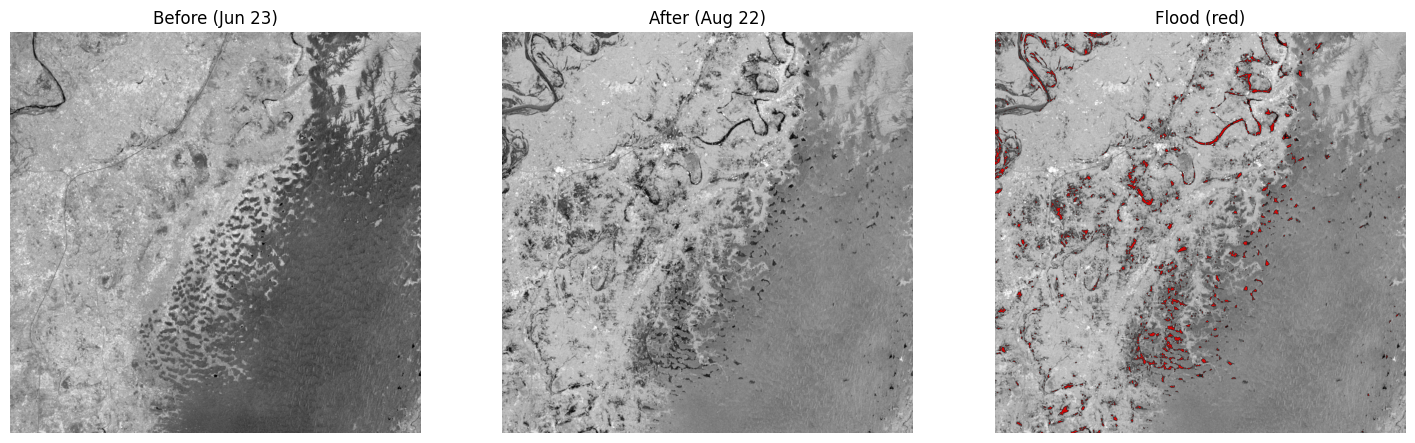

In [16]:
import rasterio, numpy as np, matplotlib.pyplot as plt
from rasterio.windows import from_bounds
from rasterio.warp import transform_bounds
from scipy.ndimage import uniform_filter

folder = "/content/drive/MyDrive/flood_project/"
bp = folder + "S1A_IW_20220623T132755_DVP_RTC30_G_gpuned_F99E_VV.tif"
ap = folder + "S1A_IW_20220822T132759_DVP_RTC30_G_gpuned_3EFC_VV.tif"

# yellow rectangle (lon/lat)
lon_min, lat_min, lon_max, lat_max = 68.1, 26.6, 68.9, 27.3

def read_crop(path):
    with rasterio.open(path) as src:
        l, b, r, t = transform_bounds("EPSG:4326", src.crs, lon_min, lat_min, lon_max, lat_max)
        win = from_bounds(l, b, r, t, src.transform)
        return src.read(1, window=win, boundless=True, fill_value=0).astype("float32")

before = read_crop(bp)
after = read_crop(ap)
h = min(before.shape[0], after.shape[0]); w = min(before.shape[1], after.shape[1])
before, after = before[:h, :w], after[:h, :w]
print("Crop shape:", before.shape)

valid = (before > 0) & (after > 0)

def to_db(x):
    x = uniform_filter(x, size=5)          # speckle filter
    return 10 * np.log10(np.where(x > 0, x, np.nan))

b_db, a_db = to_db(before), to_db(after)

water_after  = a_db < -18
water_before = b_db < -18
flood = water_after & ~water_before & valid & ((a_db - b_db) < -3)

pixel_km2 = 0.03 * 0.03   # 30m x 30m
print("Flooded area (km2):", round(flood.sum() * pixel_km2, 1))
print("Permanent water (km2):", round((water_before & valid).sum() * pixel_km2, 1))
print("Valid area (km2):", round(valid.sum() * pixel_km2, 1))

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
ax[0].imshow(b_db, cmap="gray", vmin=-25, vmax=0); ax[0].set_title("Before (Jun 23)")
ax[1].imshow(a_db, cmap="gray", vmin=-25, vmax=0); ax[1].set_title("After (Aug 22)")
ax[2].imshow(a_db, cmap="gray", vmin=-25, vmax=0)
ax[2].imshow(np.ma.masked_where(~flood, flood), cmap="autumn", alpha=0.8)
ax[2].set_title("Flood (red)")
for a in ax: a.axis("off")
plt.show()